# Step 1：带间隙约束的需求加权部署

按 **研究问题 → 方法 → 评价 → 优化参照 → 结果 → 局限** 阅读已经保存的结果。核心计算在 `src/udc/`，这里只调用包内函数并读取轨迹。

## 2026-10-19：恢复语义与非凸新seed确认 v2

冻结a0781c56，seed25–34的90行全部完成：59成功、27输入失败、4恢复预算耗尽。30个共享输入单元中21个有效；全任务59/90，有效输入任务59/63。63条已执行轨迹全量独立复判一致，实际运动区间安全全部通过。当前Guide占据不保证未来释放，完整静态路径也不保证联合执行完成。

102项测试通过，保存的宽U seed22占据案例仍安全恢复、细长seed20无恢复案例轨迹不变。新失败均在seed30（细长成对方法，宽U三方法），定位到边界航点跟随、安全过滤和有限优先恢复的执行停滞，仍未修复。Guide净裕量约1e-8m表示约束接近活跃，不表示充分噪声鲁棒性。

下一轮只优先固定四例输入和目标研究执行一致性，暂不更换估计器或部署算法。原重建v1与原九案例证据保留，不混计新样本，不追认丢失的旧11次失败。完整90行、哈希、图和命令见 `reports/step1_nonconvex_confirmation_v2/REPORT.zh.md`。下面只读取报告，不生成输入或重跑仿真。


In [1]:
from pathlib import Path
import json
confirmation_root = Path.cwd()
if not (confirmation_root / "reports").is_dir():
    confirmation_root = confirmation_root.parent
confirmation = json.loads((confirmation_root / "reports/step1_nonconvex_confirmation_v2/statistics.json").read_text(encoding="utf-8"))
print("完整90行:", confirmation["outcomes"])
print("有效输入单元:", confirmation["valid_input_units"], "/", confirmation["input_units"])
print("全部独立复判:", confirmation["executed_trajectories"], "判定不一致:", confirmation["verdict_mismatches"])
print("恢复类别:", confirmation["recovery"]["classifications"])


完整90行: {'SUCCESS': 59, 'REPLAN_EXHAUSTED': 4, 'INITIALIZATION_INVALID': 27}
有效输入单元: 21 / 30
全部独立复判: 63 判定不一致: 0
恢复类别: {'verified_path_set_installed': 19, 'priority_yield': 4, 'budget_exhausted': 4, 'current_guide_occupation': 4}


## 2026-10-19：非凸记录重建 v1 与固定目标恢复

本批是依据记录新生成的45任务，未恢复旧45的逐坐标输入。基线35成功、9输入失败、1路径失败；修复后36成功、9输入失败。原九案例执行回归9/9成功，全部88条本轮执行轨迹独立复判一致，原35条成功轨迹及原九轨迹逐坐标不变。

宽U seed21三方法本次均成功。实际失败为宽U seed22 Equal Arc，第290帧目标被另一Guide临时占据，第一次重算异常提前终止恢复。原3次预算内启用既有可达恢复、完整路径验证后成功；目标和Guide—Target映射未变，33.7s完成。不是目标不可达的证据。9行输入失败未重抽。最终94项测试和依赖检查通过。

完整协议、45行配对哈希、自由空间与恢复图、性能、版本和命令见 `reports/step1_nonconvex_record_rebuild_v1/REPORT.zh.md`。下一步聚焦固定目标下临时占据的恢复判别，不扩大矩阵。下面只读取保存报告，不运行实验。


In [ ]:
from pathlib import Path
import json
rebuild_root = Path.cwd()
if not (rebuild_root / "reports").is_dir():
    rebuild_root = rebuild_root.parent
rebuild_report = json.loads((rebuild_root / "reports/step1_nonconvex_record_rebuild_v1/summary.json").read_text(encoding="utf-8"))
print("基线:", rebuild_report["baseline"])
print("固定目标回归:", rebuild_report["repair"])
print("原九案例成功:", sum(row["success"] for row in rebuild_report["stable_nine_regression"]))
print("独立复判轨迹:", rebuild_report["all_executed_trajectories_independently_evaluated"])


## 2026-10-19：笔记本恢复核验与当前数据边界

本机仅到 b5eb3418，未取得 e2a0430 或更晚可靠版本。新增seed 20–24的45任务manifest和33任务原始输入/目标/轨迹缺失。11次PATH_UNREACHABLE尚未分层，宽U seed21三方法对照尚不能恢复；22成功、11路径失败、12输入失败仍是待独立核验的主机记录。

现有九案例保存轨迹独立复判9/9通过，没有重新仿真。完整87项、导航专项6项测试通过，uv/pip依赖检查通过。已逐文件验证并清理17979个重复backups文件，无唯一数据删除。没有新增seed、42任务回归或导航实现改动。

详细分类状态、最小迁移清单、路径/时间/裕量和命令见 `reports/step1_reachability_diagnostics.md`。下一步只优先取得原始版本与固定输入，再先诊断宽U seed21；不以旧九案例替代新增矩阵证据。下面只读取审计JSON，不生成输入、不运行控制器。


In [ ]:
from pathlib import Path
import json
audit_root = Path.cwd()
if not (audit_root / "reports").is_dir():
    audit_root = audit_root.parent
audit_report = json.loads((audit_root / "reports/step1_reachability_diagnostics.json").read_text(encoding="utf-8"))
print("原九案例离线复判:", audit_report["stable_nine_summary"])
print("新增失败已分类/已解决/未解决:", audit_report["classified_failure_count"], audit_report["resolved_failure_count"], audit_report["unresolved_failure_count"])
print("本轮执行次数:", audit_report["execution_runs_this_round"])


## 研究问题

在固定 Guide 数量下，怎样提高热点一侧的需求覆盖，同时保持最大弧间隙、最小间距和可达性。人员权重均匀并不使 Gaussian 曲线密度均匀。上一轮凸曲线上，浓度调节没有触发，因此当前要评价的是间隙投影本身。

## 方法

`projected_mass` 是带覆盖间隙约束的需求加权边界部署：在原始需求密度上做周期 CVT，每一步把弧间隙投影到 $[d_{\min}, H_p]$，并保留整体相位。RA-ABDC 使用同一次投影；只有欧氏间距仍然失败时才减半浓度。那一步在已有实验里没有发生。

数值参照用同一目标和同一积分，从 Equal Arc 与 `projected_mass` 出发做 SLSQP。它只产生目标位置，不是完整任务的最优解。

## 评价

全曲线代价是原始 Gaussian 需求下的均方弧长距离，单位 m²，越小越好。热点超额是冻结需求减去背景，核与带宽不变。局部超额达到该点需求一半的弧段不依赖 Guide。没有超额时，热点指标不适用。目标位置和实际位置分开。实际点离开曲线超过容差时单独标记，不用投影把偏离藏起来。

uniform not applicable 30
projected minus equal {'n': 90, 'mean': -0.0051322854842013755, 'min': -0.02597028876921023, 'max': -0.00025683395365425077}
rescued ratio of means 0.4014799140637096


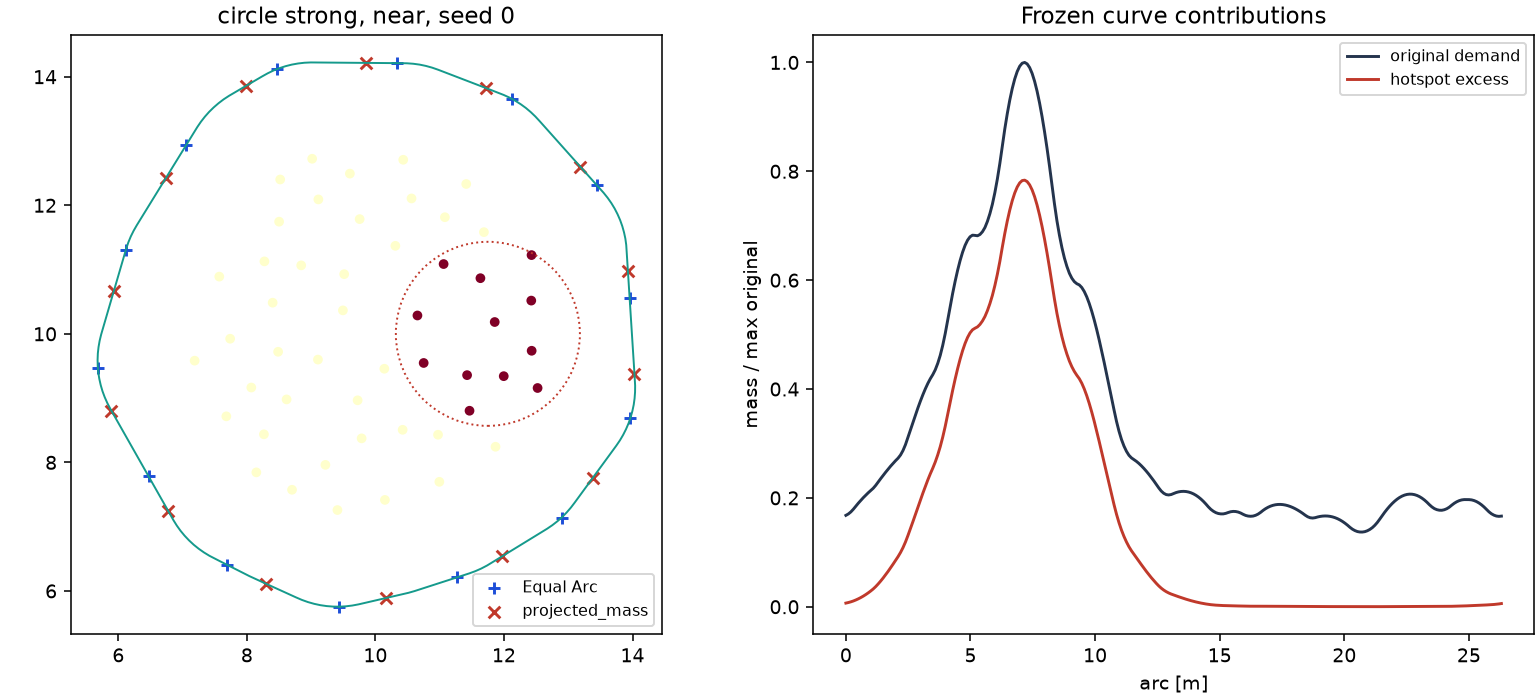

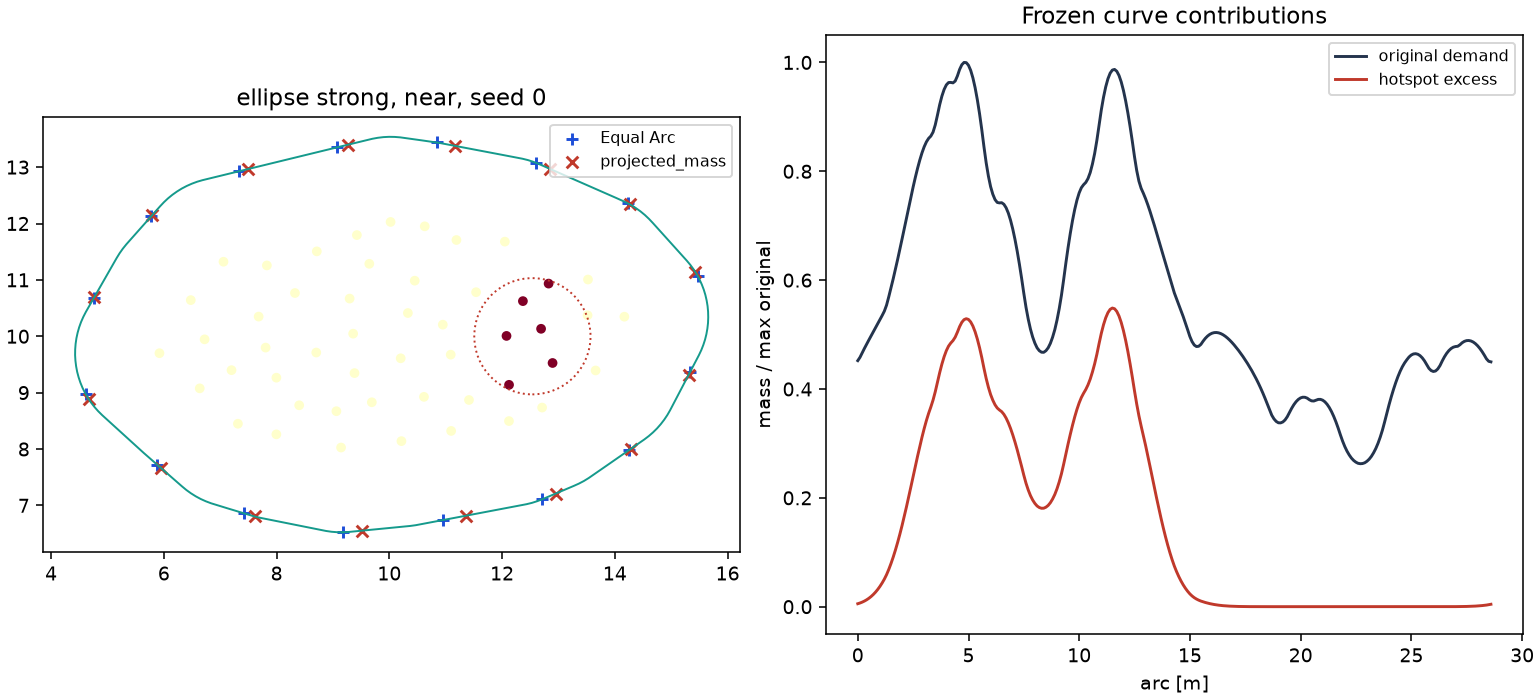

In [1]:
import json
from pathlib import Path

from IPython.display import Image, display

from udc.analysis.reanalysis import reanalyze

ROOT = Path.cwd() if (Path.cwd() / 'src' / 'udc').exists() else Path.cwd().parent
summary_path = ROOT / 'runs' / 'reproduction' / 'Kaii' / 'phase_e' / 'excess_reanalysis' / 'excess_summary.json'
if not summary_path.exists():
    reanalyze(ROOT / 'runs' / 'reproduction' / 'Kaii' / 'phase_d' / 'projection_matrix' / 'comparison.json',
              ROOT / 'runs' / 'reproduction' / 'Kaii' / 'phase_e' / 'excess_reanalysis')
summary = json.loads(summary_path.read_text(encoding='utf-8'))
print('uniform not applicable', summary['uniform_marked_not_applicable'])
print('projected minus equal', summary['projected_minus_equal_demand_cost'])
print('rescued ratio of means', summary['rescued']['demand_retention_ratio_of_means'])
for name in ('circle_strong_near_seed0.png', 'ellipse_strong_near_seed0.png'):
    display(Image(filename=str(ROOT / 'runs' / 'reproduction' / 'Kaii' / 'phase_e' / 'excess_reanalysis' / 'figures' / name)))

## 优化参照

12 个贴近数量下界的场景只做规划比较。新设备结果在 `runs/reproduction/Kaii/phase_e/reference` 和 `reference_sensitivity`。参照相对 `projected_mass` 的改进约为 0.00020–0.00527 m²。圆形强热点大约 0.004–0.0046 m²。椭圆强热点 seed 0 是 0.00157 m²，大于旧设备文字里的 0.0004 m²。积分点从 1024 增到 4096 时，圆形强热点 seed 0 的改进仍是 0.00402、0.00406、0.00409。

## 结果

90 对里，`projected_mass` 的全曲线规划代价都低于 Equal Arc，均值差 −0.00513 m²。Mass CVT 已经可行的 62 对上，二者几乎相同。28 个原先不可行的任务被投影修复；三个规划代价的均值是 0.275789、0.282797、0.287497，投影留下约 40.1% 的无约束代价改进。这只描述这 28 个任务，不是全体任务的性能涨幅。

多初值参照能再降一点代价，尤其是圆形强热点，但没有找到另一类明显更好的可行方案。若干次迭代达到上限，独立检查仍然可行；上限用尽不是不可行。

## 正式验证

种子 5000–5029 的 1620 个任务与上面的开发重跑分开。Equal Arc 和 `projected_mass` 都是 540/540。Mass CVT 是 377/540，163 次失败都是规划搜索耗尽，投影后都通过验收。没有指派失败或执行失败。

540 对规划需求代价都低于 Equal Arc。种子均值差 −0.00493 m²，95% 区间 [−0.00521, −0.00467]。逐对相对差的均值是 −2.47%，总体均值之比是 −2.30%。这是较小的覆盖收益，不是成功率优势。强热点超额代价全部更低；180 个弱热点里有 11 对超额代价略高。背景代价的种子均值高 0.00110 m²。路径平均长 0.324 m，部署时间平均多 0.035 s，规划时间平均多 0.047 s。实际最大间隙平均从 1.590 m 增到 1.746 m，仍通过原有验收。

图在 `runs/formal/step1_projection_v1/figures/`。中位配对和最差配对都是圆形、弱热点、N=14，种子分别是 5010 和 5023。没有 Equal Arc 成功而 `projected_mass` 失败的单元。

{'units': 540, 'mass_cvt_succeeded_units': 377, 'projection_rescued_units': 163, 'projected_failed_or_worse_cost_units': 0, 'planned_cost_pairs': 540}
{'seeds': 30, 'mean': -0.004932182635013109, 'ci95': [-0.005204773706388359, -0.004665340880981976]}


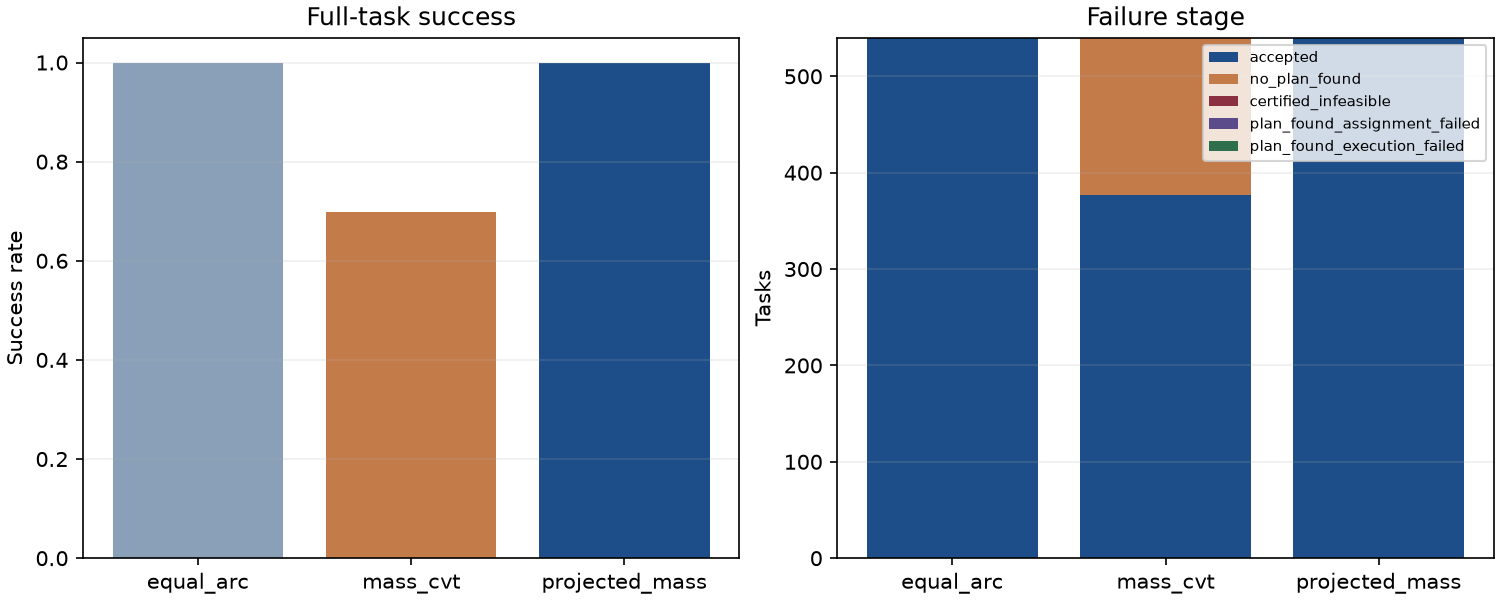

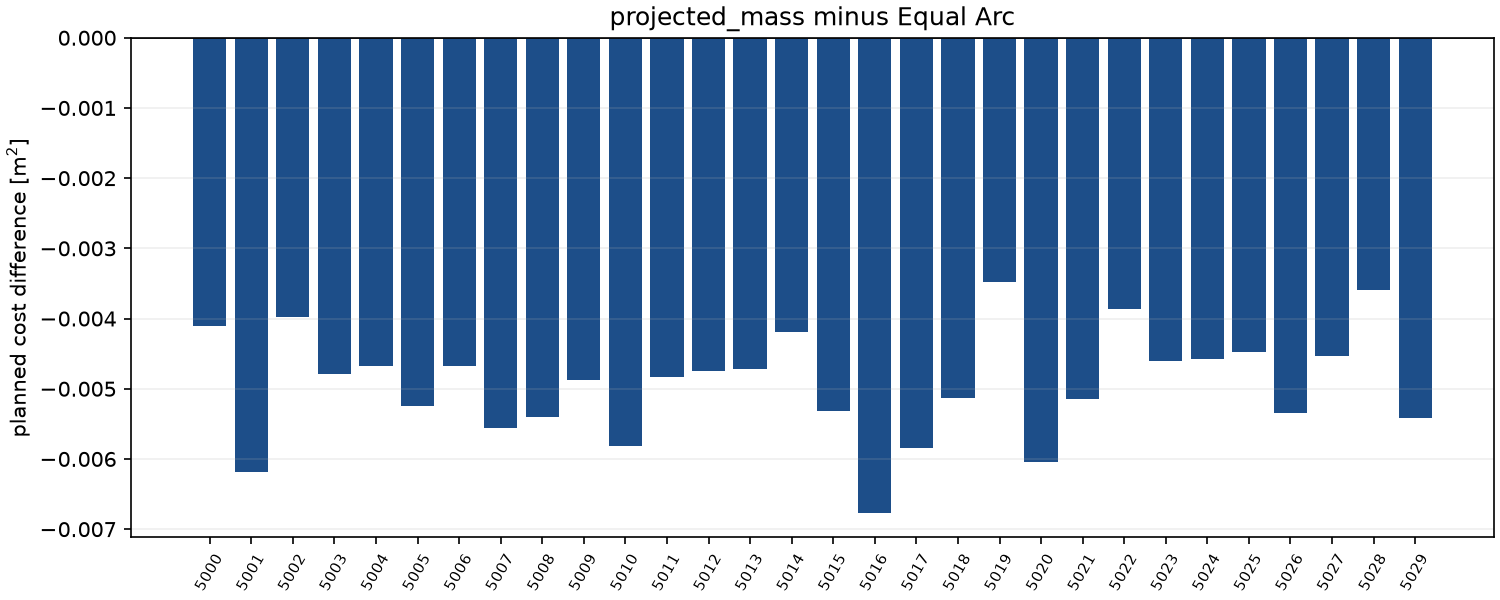

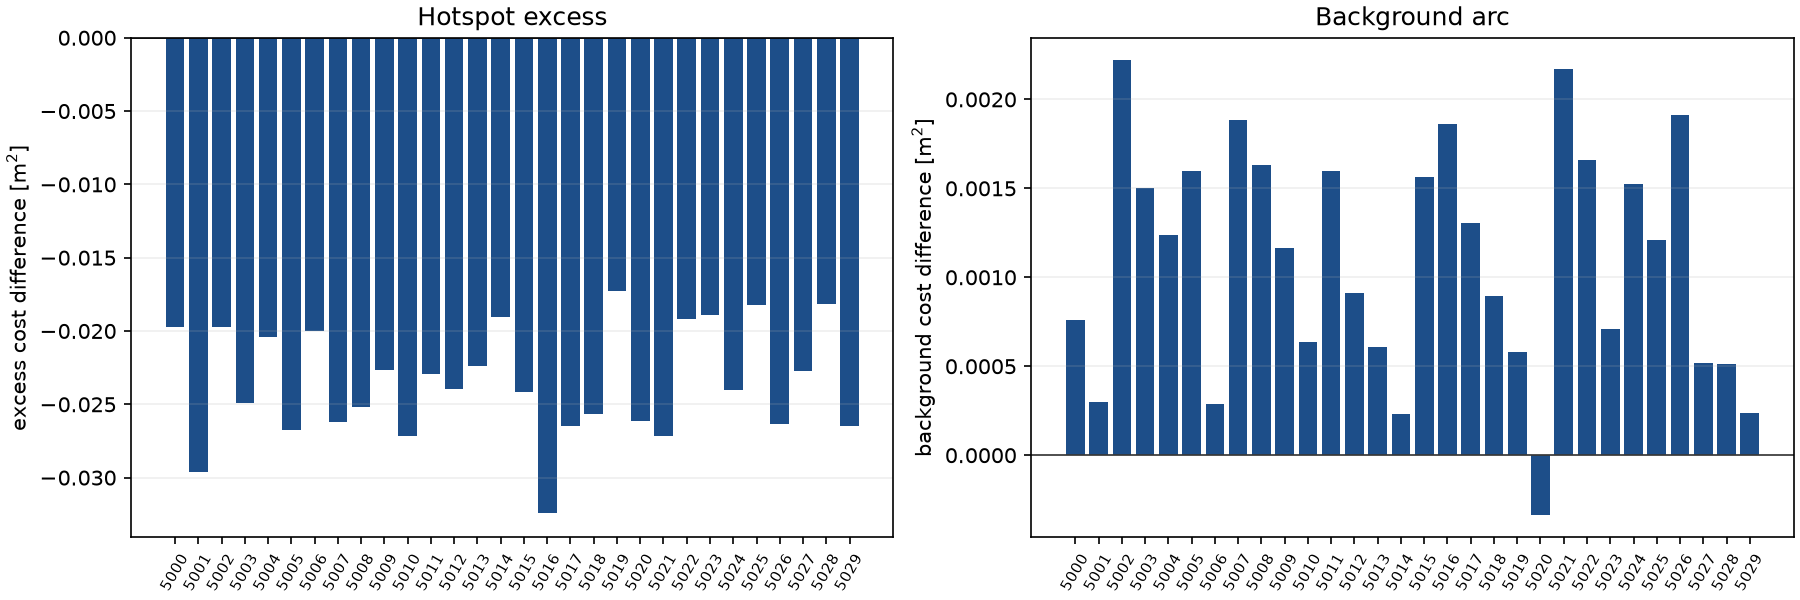

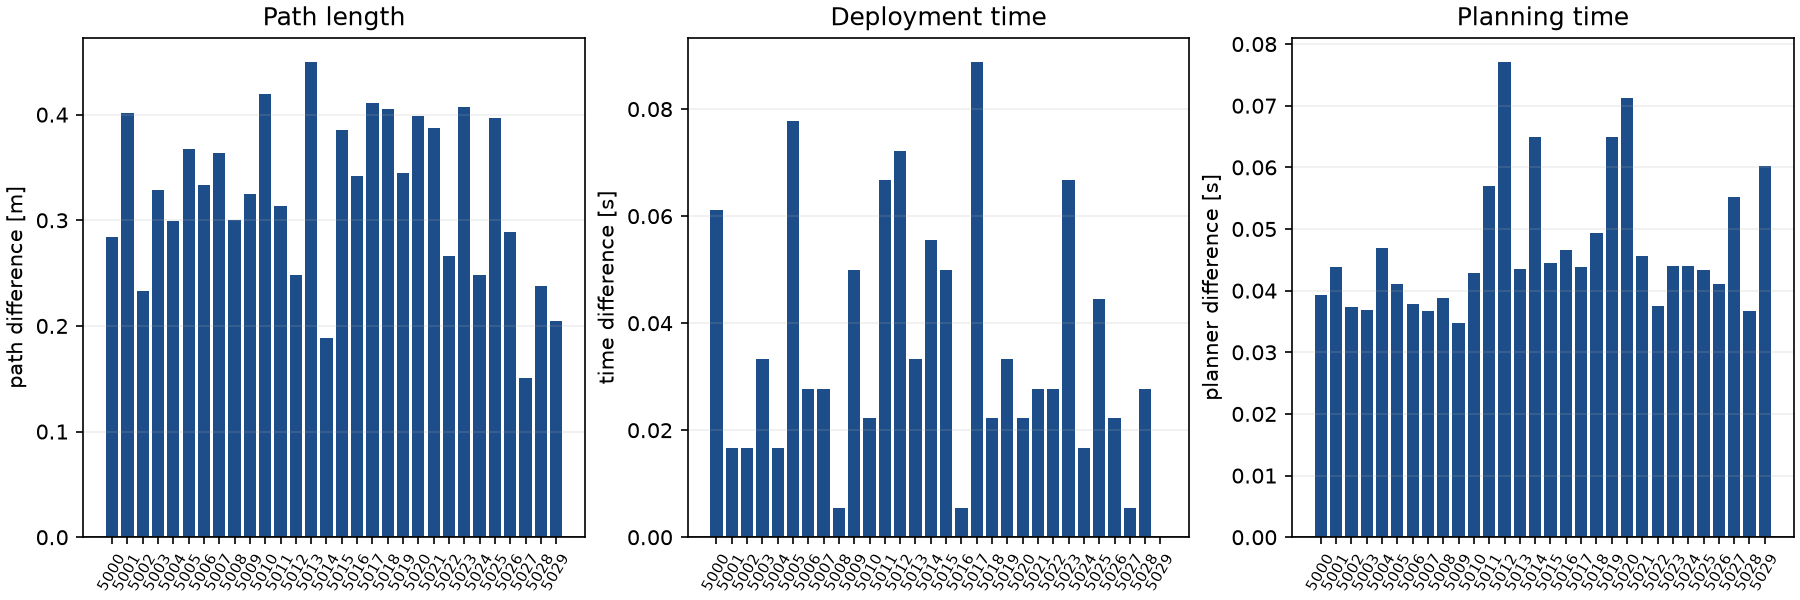

In [2]:
import json
from pathlib import Path

from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / 'src' / 'udc').exists() else Path.cwd().parent
formal = json.loads((ROOT / 'runs' / 'formal' / 'step1_projection_v1' / 'formal_report.json').read_text(encoding='utf-8'))
paired = formal['overall']['paired']['projected_mass']['planned_demand_weighted_cost']
print(formal['slice_counts'])
print(paired['seed_cluster'])
for name in ('success_stages.png', 'demand_cost_deltas.png', 'hotspot_background.png', 'cost_of_deployment.png'):
    display(Image(filename=str(ROOT / 'runs' / 'formal' / 'step1_projection_v1' / 'figures' / name)))

## 局限

数量界只在“目标位于这一条曲线、弦长不超过弧长”时是必要条件。投影保证的是弧间隙盒子里的数值可行点，不保证原始目标下降、全局最优或欧氏间距。可达和执行安全仍由原有导航与线段复核负责。浓度调节没有被检验。

正式结果仍限于一个静态人群、凸部署曲线、已知场地和全局观测。需求是规划权重。旧设备数值参照里椭圆强热点 seed 0 的连续量差异留在记录中，没有为追平它而改预算。

## 一般曲线：弧间隙与欧氏间距

问题仍是单个静态人群、全局观测、无人群–Guide 作用。这一节不估计未知边界。曲线是给定的，用来看弧间隙已经合格时，哪些形状仍会让目标的欧氏距离低于 0.75 m。正常观测仍走凸包外偏移。

周长固定为 32 m。两档数量在跑之前写死：`near = ceil(L/1.94) = 17`，`margin = ceil(L/(0.75 π/2)) = 28`。0.75 m 是中心距 `2×0.20+0.35`，不是净距。seed 15–19 只旋转参数起点。需求是曲线上的常数密度。

![六条冻结曲线](../runs/step1_general_curve/figures/prescribed_curves.png)

30/30 条曲线有效。300 个规划任务里，271 个目标几何可行，29 个是弧间隙通过但欧氏间距失败。没有一个被标成完整部署成功。失败都在槽宽 0.45 m 的深槽：N=28 全部失败，最近一对是槽壁上的非相邻目标，距离约 0.45 m。

![窄槽上的非相邻冲突](../runs/step1_general_curve/figures/conflict_0_deep_notch_narrow_margin_seed15.png)

强胶囊在 N=28 时，最近一对是端帽上的相邻弦，0.948 m，仍高于 0.75 m。这个参数范围内没有凸曲线失败。

![高曲率端帽上的相邻弦](../runs/step1_general_curve/figures/conflict_7_high_curvature_convex_strong_margin_seed15.png)

In [ ]:
import json
from pathlib import Path

summary = json.loads(Path('../reports/step1_general_curve_summary.json').read_text(encoding='utf-8'))
print('tasks', summary['tasks'], 'valid curves', summary['valid_curves'])
print('classes', summary['classes'])
print('statuses', summary['statuses'])
print('by method', summary['by_method'])
print('execution tasks', summary['execution_tasks'])
print(summary['scope'])

## 执行案例与局限

只有几何可行、并且曲线向内 1.6 m 后仍放得下人员的单元才执行。强胶囊和窄槽的内缩面积是 0，没有轨迹。窄槽余量档是规划拒绝，也不执行。

实际执行的是浅凹、N=17、seed 15 的 Equal Arc、Mass CVT 和 `projected_mass`。三条都到达，路径和安全通过，离线复判一致。正式状态仍是 `COVERAGE_NOT_MET`：目标到曲线的 Shapely 距离是 1.7×10⁻⁷ 到 4.0×10⁻⁷ m，超过既有的 10⁻⁷ m 检查。弧间隙和欧氏间距本身合格。没有放宽这个阈值。

![浅凹上的三次执行](../runs/step1_general_curve/figures/execution_shallow_strong_near_seed15.png)

均匀密度下，除 DistMesh 在一条窄槽对齐上有约 0.6 m 的移位外，几种方法几乎重合。这不是需求覆盖方法的排名。`projected_mass` 只投影相邻弧间隙，约束不了槽壁两侧的非相邻点。

下一步应给目标配置加上全部成对欧氏间距。曲线生成在这 30 条上是有效的。浅凹案例的导航可以到达。本轮曲线是给定的，不能换成“边界估计已经解决”。不进入多人群、动态人群和有限通信。

## 贴线交接与成对间距

上一节三次浅凹执行的 COVERAGE_NOT_MET 仍保留在原始目录。独立复算表明：规划曲线和评价曲线一致，全精度目标离曲线约 1e-15 m，失败来自 geometry.json 把坐标保留到六位小数。跟踪误差约 0.0037 m，在 0.03 m 容差内。1e-7 m 阈值没有改。用弧坐标重新插值后，三次新执行都是 SUCCESS。

十二个冻结单元、四条规划路径，共 48 个任务。Equal Arc 和 projected_mass 各有 10 个可行见证，只调相位 11 个，全部成对欧氏约束 12 个。未找到的都在 0.45 m 窄槽。N=17 的那条对齐只调相位就能修好；N=28 不行，成对约束找到了距离恰好 0.75 m 的配置，常数密度代价增加约 0.00026 平方米。求解器的成功标志和迭代上限都不是独立验收。

In [ ]:
import json
from pathlib import Path

constant = json.loads(Path('../reports/step1_curve_constraints_summary.json').read_text(encoding='utf-8'))
print('constant outcomes', constant['outcomes'])
print('by method', constant['by_method'])
repair = json.loads(Path('../reports/step1_adhesion_rerun.json').read_text(encoding='utf-8'))
print('adhesion cause', repair['diagnosis_cause'])
for row in repair['results']:
    print(row['method'], row['termination_status'], row['success'], row['target_curve_distance_max_m'])
execution = json.loads(Path('../reports/step1_scene_closure_execution.json').read_text(encoding='utf-8'))
print('scene tasks', execution['tasks_executed'])
for row in execution['rows']:
    print(row['scene'], row['method'], row.get('termination_status'), row.get('success'))


## 有效人群里的曲线

1.6 m 内缩是给定曲线附着程序的参数，不是 Guide–人 0.75 m 或外偏移 1.3 m 的安全距离。凹陷估计用圆盘并集再外偏移，只读人员位置和半径。凸包仍会把凹陷填平。

间距 0.80 m 的紧凑网格在闭运算半径 0.30 m 下没有连成一条曲线。细长排列、宽 U 和窄 U 在 1.3 m 偏移下有效。它们弧长相距超过 2 m 的自接近都大于 0.75 m，目标最近距离也都不低于 1.37 m。0.45 m 窄槽没有在这些有效场景里出现。

细长和窄 U 的六次执行通过验收。宽 U 的三次目标可行，初始路径检查也通过，但执行中的路径重算报告端点不在保守自由空间内。这不证明从初态不存在路径。下一轮应先处理这条可实现的凹曲线，而不是继续扩大 0.45 m 的给定曲线反例。